# Task 2 — Notebook 2: Create the Target Label

This notebook creates the binary target `is_late` from the order-level table produced by Notebook 1.

**Label rule:**

- `is_late = 1` when the actual delivery date is after the estimated delivery date.
- `is_late = 0` when the actual delivery date is on or before the estimated delivery date.

Only delivered orders with both required dates are included. Orders without a reliable delivery outcome are excluded from the labeled dataset.

**Input:** `artifacts/tables/01_joined_ml_table.parquet`

**Output:** `artifacts/tables/02_labeled_table.parquet`


## 1. Imports and paths

The paths below follow the compact Task 2 artifact structure. This notebook does not connect to PostgreSQL directly; it reads the clean order-level artifact from Notebook 1.


In [1]:
from pathlib import Path
import json

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

import sys

src_dir = Path.cwd().resolve()
while src_dir != src_dir.parent and not (src_dir / "Task2").is_dir():
    src_dir = src_dir.parent
src_dir = src_dir / "Task2" / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from config import find_project_root

PROJECT_ROOT = find_project_root()
TASK2_ROOT = PROJECT_ROOT / "Task2"
ARTIFACTS_DIR = TASK2_ROOT / "artifacts"
TABLES_DIR = ARTIFACTS_DIR / "tables"
REPORTS_DIR = ARTIFACTS_DIR / "reports"
CHARTS_DIR = ARTIFACTS_DIR / "charts"

for folder in [TABLES_DIR, REPORTS_DIR, CHARTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

input_path = TABLES_DIR / "01_joined_ml_table.parquet"
output_path = TABLES_DIR / "02_labeled_table.parquet"
metadata_path = REPORTS_DIR / "02_labeled_table_metadata.json"
plot_path = CHARTS_DIR / "02_label_distribution.png"

if not input_path.exists():
    raise FileNotFoundError(f"Input artifact not found: {input_path}")

print(f"Reading: {input_path}")


Reading: C:\Users\HP\Desktop\MLOps\Task2\artifacts\tables\01_joined_ml_table.parquet


## 2. Load the order-level table and parse dates

The source database stores date columns as text. We convert the relevant columns explicitly so that the comparison is reliable.


In [2]:
df = pd.read_parquet(input_path)

required_columns = [
    "order_id",
    "order_status",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

missing_columns = sorted(set(required_columns) - set(df.columns))
assert not missing_columns, f"Missing required columns: {missing_columns}"

for column in [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]:
    if column in df.columns:
        df[column] = pd.to_datetime(df[column], errors="coerce")

print(f"Input rows: {len(df):,}")
display(df[required_columns].head())


Input rows: 99,441


,order_id,order_status,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,2018-02-16 18:17:02,2018-02-26


## 3. Keep only orders with a reliable outcome

A late-delivery label is meaningful only when the order is delivered and both actual and estimated delivery dates are available.


In [3]:
required_dates = [
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

valid_rows = (
    (df["order_status"] == "delivered")
    & df[required_dates].notna().all(axis=1)
)

labeled = df.loc[valid_rows].copy()

print(f"Rows eligible for labeling: {len(labeled):,}")
print(f"Rows excluded: {len(df) - len(labeled):,}")


Rows eligible for labeling: 96,470
Rows excluded: 2,971


## 4. Create `is_late`

The comparison is intentionally simple and transparent. Equal dates are classified as `on_time`.


In [4]:
labeled["is_late"] = (
    labeled["order_delivered_customer_date"]
    > labeled["order_estimated_delivery_date"]
).astype("int8")

labeled = labeled.sort_values("order_purchase_timestamp").reset_index(drop=True)

assert labeled["order_id"].is_unique, "There must be one row per order_id."
assert labeled["is_late"].notna().all()
assert set(labeled["is_late"].unique()) == {0, 1}

display(labeled[[
    "order_id",
    "order_status",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "is_late",
]].head())


,order_id,order_status,order_delivered_customer_date,order_estimated_delivery_date,is_late
0,bfbd0f9bdef84302105ad712db648a6c,delivered,2016-11-09 07:47:38,2016-10-04,1
1,3b697a20d9e427646d92567910af6d57,delivered,2016-10-26 14:02:13,2016-10-27,0
2,be5bc2f0da14d8071e2d45451ad119d9,delivered,2016-10-27 18:19:38,2016-11-07,0
3,a41c8759fbe7aab36ea07e038b2d4465,delivered,2016-11-03 10:58:07,2016-11-29,0
4,d207cc272675637bfed0062edffd0818,delivered,2016-10-31 11:07:42,2016-11-23,0


## 5. Validate the label with real orders

The validation table shows examples from both classes and independently recomputes the rule. This makes the target definition easy to audit.


In [5]:
examples = pd.concat([
    labeled[labeled["is_late"] == 0].head(3),
    labeled[labeled["is_late"] == 1].head(3),
]).drop_duplicates("order_id")

examples = examples[[
    "order_id",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "is_late",
]].copy()

examples["rule_check"] = (
    examples["order_delivered_customer_date"]
    > examples["order_estimated_delivery_date"]
).astype("int8")

examples["label_name"] = examples["is_late"].map({0: "on_time", 1: "late"})
display(examples)

assert (examples["rule_check"] == examples["is_late"]).all()
print("The label rule matches the sampled real orders.")


,order_id,order_delivered_customer_date,order_estimated_delivery_date,is_late,rule_check,label_name
1,3b697a20d9e427646d92567910af6d57,2016-10-26 14:02:13,2016-10-27,0,0,on_time
2,be5bc2f0da14d8071e2d45451ad119d9,2016-10-27 18:19:38,2016-11-07,0,0,on_time
3,a41c8759fbe7aab36ea07e038b2d4465,2016-11-03 10:58:07,2016-11-29,0,0,on_time
0,bfbd0f9bdef84302105ad712db648a6c,2016-11-09 07:47:38,2016-10-04,1,1,late
42,b0cfee6ce5503781be6004e0e31e4309,2016-11-29 15:23:44,2016-11-28,1,1,late
52,5cc475c7c03290048eb2e742cd64cb5e,2016-12-12 20:31:54,2016-11-24,1,1,late


The label rule matches the sampled real orders.


## 6. Inspect class balance

Late delivery is expected to be the minority class. We calculate counts and percentages before saving the artifact so later modeling decisions are based on the actual distribution.


In [6]:
class_distribution = (
    labeled["is_late"]
    .value_counts()
    .rename_axis("is_late")
    .reset_index(name="count")
    .sort_values("is_late")
)

class_distribution["label_name"] = class_distribution["is_late"].map({0: "on_time", 1: "late"})
class_distribution["percentage"] = (
    class_distribution["count"] / len(labeled) * 100
)

display(class_distribution[["is_late", "label_name", "count", "percentage"]])

imbalance_ratio = (
    class_distribution["count"].max() / class_distribution["count"].min()
)
print(f"Imbalance ratio: {imbalance_ratio:.2f}")


,is_late,label_name,count,percentage
0,0,on_time,88644,91.887633
1,1,late,7826,8.112367


Imbalance ratio: 11.33


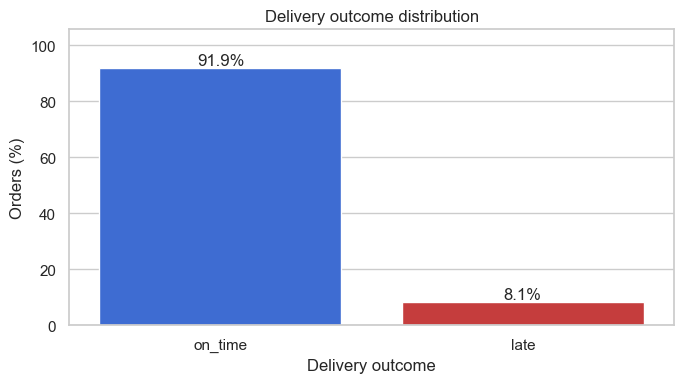

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    data=class_distribution,
    x="label_name",
    y="percentage",
    order=["on_time", "late"],
    palette=["#2563eb", "#dc2626"],
    hue="label_name",
    legend=False,
    ax=ax,
)
ax.set_title("Delivery outcome distribution")
ax.set_xlabel("Delivery outcome")
ax.set_ylabel("Orders (%)")
ax.set_ylim(0, max(class_distribution["percentage"]) * 1.15)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.show()
fig.savefig(plot_path, dpi=150, bbox_inches="tight")


## 7. Save the labeled artifact and metadata


In [8]:
labeled.to_parquet(output_path, index=False)

metadata = {
    "artifact": str(output_path),
    "grain": "one row per order_id",
    "rows": int(len(labeled)),
    "columns": int(len(labeled.columns)),
    "target": "is_late",
    "target_definition": "1 when actual delivery is after estimated delivery; otherwise 0",
    "included_rule": "order_status is delivered and both delivery dates are present",
    "excluded_rows": int(len(df) - len(labeled)),
    "class_counts": {
        str(int(row.is_late)): int(row.count)
        for row in class_distribution.itertuples()
    },
}

metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print(f"Saved: {output_path}")
print(f"Saved: {metadata_path}")
print(f"Saved: {plot_path}")


Saved: C:\Users\HP\Desktop\MLOps\Task2\artifacts\tables\02_labeled_table.parquet
Saved: C:\Users\HP\Desktop\MLOps\Task2\artifacts\reports\02_labeled_table_metadata.json
Saved: C:\Users\HP\Desktop\MLOps\Task2\artifacts\charts\02_label_distribution.png


## 8. Final checks


In [9]:
reloaded = pd.read_parquet(output_path)

assert output_path.exists()
assert reloaded["order_id"].is_unique
assert reloaded["is_late"].notna().all()
assert set(reloaded["is_late"].unique()) == {0, 1}
assert len(reloaded) == len(labeled)

print("ALL NOTEBOOK 2 CHECKS PASSED")


ALL NOTEBOOK 2 CHECKS PASSED
